In [31]:
%pip install --upgrade bottleneck

Note: you may need to restart the kernel to use updated packages.


In [3]:
import bottleneck as bn
print(bn.__version__)

1.4.2


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [33]:
df = pd.read_csv("C:\\Users\\SAVITRI\\Downloads\\social_media_sentiment_dataset.csv")

df.head()

,review_id,date,platform,username,topic,review_text,likes,sentiment
0,1,2025-08-17,Twitter,user_0693,Technology,"In my opinion, Very disappointed with this pro...",2233,Negative
1,2,2025-04-06,Instagram,user_0518,Delivery,Excellent service. The team solved my issue qu...,108,Positive
2,3,2026-04-05,Facebook,user_0007,Customer Service,Update: Bad experience. I regret buying this. ...,1731,Negative
3,4,2025-04-15,YouTube,user_0100,Mobile App,"Honestly, Very happy with my purchase, highly ...",1408,Positive
4,5,2025-05-08,Twitter,user_0566,Mobile App,Update: Very disappointed with this product. I...,1481,Negative


In [34]:
df.shape

(5000, 8)

In [35]:
df.columns

Index(['review_id', 'date', 'platform', 'username', 'topic', 'review_text',
       'likes', 'sentiment'],
      dtype='str')

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    5000 non-null   int64
 1   date         5000 non-null   str  
 2   platform     5000 non-null   str  
 3   username     5000 non-null   str  
 4   topic        5000 non-null   str  
 5   review_text  5000 non-null   str  
 6   likes        5000 non-null   int64
 7   sentiment    5000 non-null   str  
dtypes: int64(2), str(6)
memory usage: 864.9 KB


In [37]:
df.describe()

,review_id,likes
count,5000.000000,5000.000000
mean,2500.500000,1270.538200
std,1443.520003,726.077978
min,1.000000,1.000000
25%,1250.750000,642.750000
50%,2500.500000,1281.500000
75%,3750.250000,1900.000000
max,5000.000000,2500.000000


In [38]:
df.isnull().sum()

review_id      0
date           0
platform       0
username       0
topic          0
review_text    0
likes          0
sentiment      0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Clean Dataset:", df_clean.shape)

Original Dataset: (5000, 8)
Clean Dataset: (5000, 8)


In [42]:
df_clean.isnull().sum()

review_id      0
date           0
platform       0
username       0
topic          0
review_text    0
likes          0
sentiment      0
dtype: int64

In [43]:
df_clean=df_clean.dropna()
print("After Removing Missing Values:",df_clean.shape)

After Removing Missing Values: (5000, 8)


In [44]:
print("Duplicate Records:",df_clean.duplicated().sum())
df_clean =df_clean.drop_duplicates()
print("After Removing Duplicates:",df_clean.shape)

Duplicate Records: 0
After Removing Duplicates: (5000, 8)


In [45]:
#date column convert
df_clean["date"]=pd.to_datetime(df_clean["date"])
df_clean["date"].dtype

dtype('<M8[us]')

In [46]:
#text data cleaning
df_clean["review_text"] = df_clean["review_text"].str.strip()

df_clean["review_text"] = df_clean["review_text"].str.lower()

df_clean["platform"] = df_clean["platform"].str.strip()

df_clean["sentiment"] = df_clean["sentiment"].str.strip().str.title()

In [47]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   review_id    5000 non-null   int64         
 1   date         5000 non-null   datetime64[us]
 2   platform     5000 non-null   str           
 3   username     5000 non-null   str           
 4   topic        5000 non-null   str           
 5   review_text  5000 non-null   str           
 6   likes        5000 non-null   int64         
 7   sentiment    5000 non-null   str           
dtypes: datetime64[us](1), int64(2), str(5)
memory usage: 816.9 KB


In [48]:
df_clean.head()

,review_id,date,platform,username,topic,review_text,likes,sentiment
0,1,2025-08-17,Twitter,user_0693,Technology,"in my opinion, very disappointed with this pro...",2233,Negative
1,2,2025-04-06,Instagram,user_0518,Delivery,excellent service. the team solved my issue qu...,108,Positive
2,3,2026-04-05,Facebook,user_0007,Customer Service,update: bad experience. i regret buying this. ...,1731,Negative
3,4,2025-04-15,YouTube,user_0100,Mobile App,"honestly, very happy with my purchase, highly ...",1408,Positive
4,5,2025-05-08,Twitter,user_0566,Mobile App,update: very disappointed with this product. i...,1481,Negative


In [49]:
df_clean.to_csv("cleaned_social_media_reviews.csv", index=False)

print("Clean Dataset Saved Successfully!")

Clean Dataset Saved Successfully!


In [50]:
print("Total Reviews:", len(df_clean))

Total Reviews: 5000


In [51]:
#sentiment count analysis
sentiment_count = df_clean["sentiment"].value_counts()

print(sentiment_count)

sentiment
Positive    2005
Negative    1751
Neutral     1244
Name: count, dtype: int64


In [52]:
sentiment_percentage = df_clean["sentiment"].value_counts(normalize=True) * 100

print(sentiment_percentage.round(2))

sentiment
Positive    40.10
Negative    35.02
Neutral     24.88
Name: proportion, dtype: float64


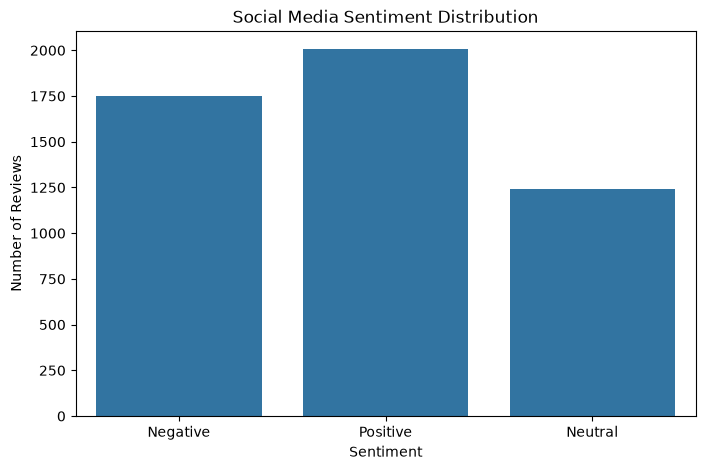

In [53]:
#Sentiment Visualization
plt.figure(figsize=(8,5))

sns.countplot(data=df_clean, x="sentiment")

plt.title("Social Media Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [28]:
likes_analysis = df_clean.groupby("sentiment")["likes"].mean()

print(likes_analysis)

sentiment
Negative    1272.330668
Neutral     1273.942926
Positive    1266.860349
Name: likes, dtype: float64


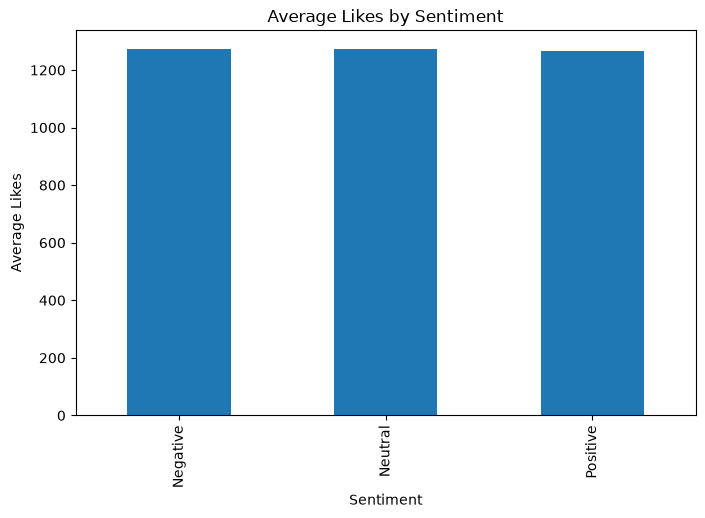

In [54]:
likes_analysis.plot(kind="bar", figsize=(8,5))

plt.title("Average Likes by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Likes")

plt.show()

In [55]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [56]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
print("NLTK Imported Successfully!")


NLTK Imported Successfully!


In [57]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\SAVITRI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\SAVITRI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\SAVITRI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [58]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

text = "I love this product and it works perfectly"

tokens = word_tokenize(text.lower())

print("Tokens:", tokens)

Tokens: ['i', 'love', 'this', 'product', 'and', 'it', 'works', 'perfectly']


In [59]:
stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in tokens
    if word not in stop_words
]

print("Filtered Words:", filtered_words)

Filtered Words: ['love', 'product', 'works', 'perfectly']


In [60]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [67]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [70]:
print(df_clean.columns.tolist())

['review_id', 'date', 'platform', 'username', 'topic', 'review_text', 'likes', 'sentiment']


In [72]:
import pandas as pd
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# 1. Create cleaned text
df_clean["cleaned_text"] = df_clean["review_text"].fillna("").astype(str)

# 2. Convert into lowercase
df_clean["cleaned_text"] = df_clean["cleaned_text"].str.lower()

# 3. Remove special characters
df_clean["cleaned_text"] = df_clean["cleaned_text"].apply(
    lambda text: re.sub(r"[^a-zA-Z\s]", "", text)
)

# 4. Tokenization
df_clean["tokens"] = df_clean["cleaned_text"].apply(
    word_tokenize
)

# 5. Stopwords
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor"}

df_clean["filtered_tokens"] = df_clean["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

# 6. Final text
df_clean["final_text"] = df_clean["filtered_tokens"].apply(
    lambda words: " ".join(words)
)

print("Text Preprocessing Completed Successfully!")

Text Preprocessing Completed Successfully!


In [73]:
df_clean[["review_text", "cleaned_text", "final_text"]].head()

,review_text,cleaned_text,final_text
0,"in my opinion, very disappointed with this pro...",in my opinion very disappointed with this prod...,opinion disappointed product stopped working r...
1,excellent service. the team solved my issue qu...,excellent service the team solved my issue qui...,excellent service team solved issue quickly
2,update: bad experience. i regret buying this. ...,update bad experience i regret buying this review,update bad experience regret buying review
3,"honestly, very happy with my purchase, highly ...",honestly very happy with my purchase highly re...,honestly happy purchase highly recommended think
4,update: very disappointed with this product. i...,update very disappointed with this product it ...,update disappointed product stopped working


In [74]:
all_text = " ".join(df_clean["final_text"].dropna())

print(all_text[:500])

opinion disappointed product stopped working review excellent service team solved issue quickly update bad experience regret buying review honestly happy purchase highly recommended think update disappointed product stopped working terrible experience poor customer service review honestly unhappy quality complete waste think today delivery late package damaged review app smooth useful easy use review opinion update released morning review today great value money reliable quality think today serv


In [75]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [80]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

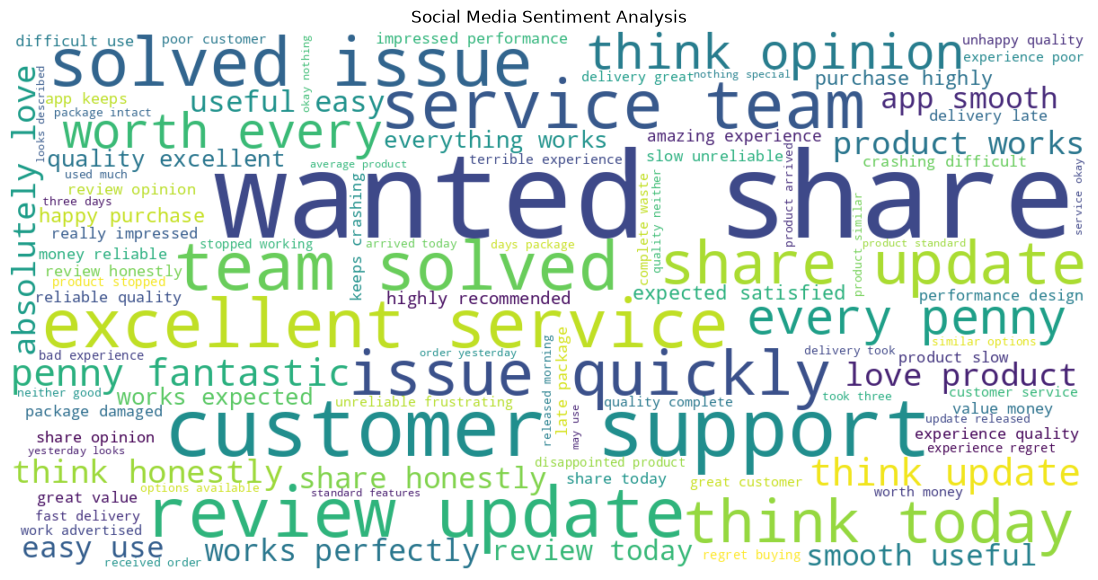

In [81]:
all_text = " ".join(df_clean["final_text"].dropna())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(all_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Social Media Sentiment Analysis")
plt.show()

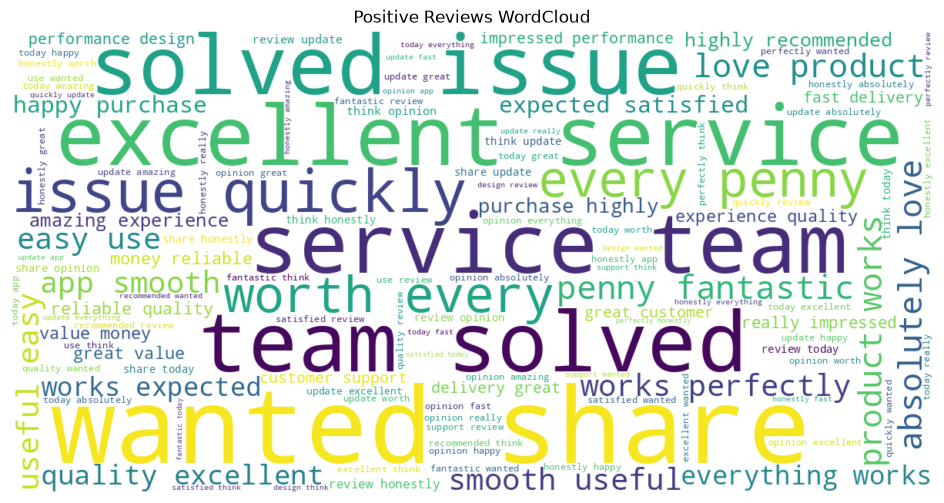

In [82]:
positive_text = " ".join(
    df_clean.loc[
        df_clean["sentiment"] == "Positive",
        "final_text"
    ].dropna()
)

positive_wc = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(14, 6))
plt.imshow(positive_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Reviews WordCloud")
plt.show()

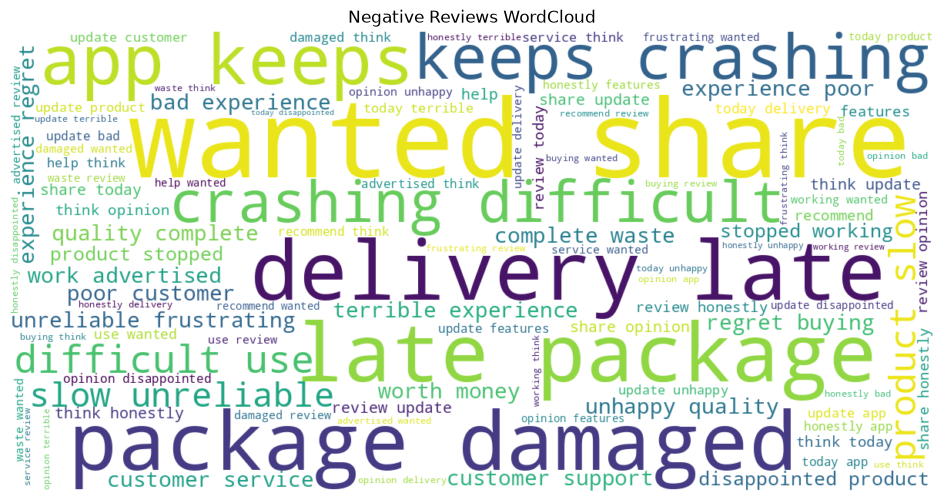

In [83]:
negative_text = " ".join(
    df_clean.loc[
        df_clean["sentiment"] == "Negative",
        "final_text"
    ].dropna()
)

negative_wc = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(14, 6))
plt.imshow(negative_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Reviews WordCloud")
plt.show()

In [84]:
wordcloud.to_file("social_media_wordcloud.png")
positive_wc.to_file("positive_wordcloud.png")
negative_wc.to_file("negative_wordcloud.png")

print("All WordCloud Images Saved Successfully!")

All WordCloud Images Saved Successfully!


In [88]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [89]:
X = df_clean["final_text"]

y = df_clean["sentiment"]

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (5000,)
Output Shape: (5000,)


In [92]:
tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(X)
print("TF-IDF Shape:", X_tfidf.shape)

TF-IDF Shape: (5000, 399)


In [94]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [95]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (4000, 399)
Testing Data: (1000, 399)
Training Labels: (4000,)
Testing Labels: (1000,)


In [96]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:20])

['absolutely' 'absolutely love' 'advertised' 'advertised review'
 'advertised think' 'advertised wanted' 'amazing' 'amazing experience'
 'app' 'app keeps' 'app several' 'app smooth' 'arrived' 'arrived today'
 'available' 'available review' 'available think' 'available wanted'
 'average' 'average product']


In [97]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X = df_clean["final_text"].fillna("").astype(str)
y = df_clean["sentiment"]

# Split data
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TF-IDF
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4000, 399)
Testing Data: (1000, 399)


In [98]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [99]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
['Positive' 'Neutral' 'Positive' 'Negative' 'Positive' 'Negative'
 'Neutral' 'Negative' 'Negative' 'Positive']


In [100]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 1.0
Accuracy Percentage: 100.0 %


In [101]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
['Positive' 'Neutral' 'Positive' 'Negative' 'Positive' 'Negative'
 'Neutral' 'Negative' 'Negative' 'Positive']


In [102]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 1.0
Accuracy Percentage: 100.0 %


In [103]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       350
     Neutral       1.00      1.00      1.00       249
    Positive       1.00      1.00      1.00       401

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



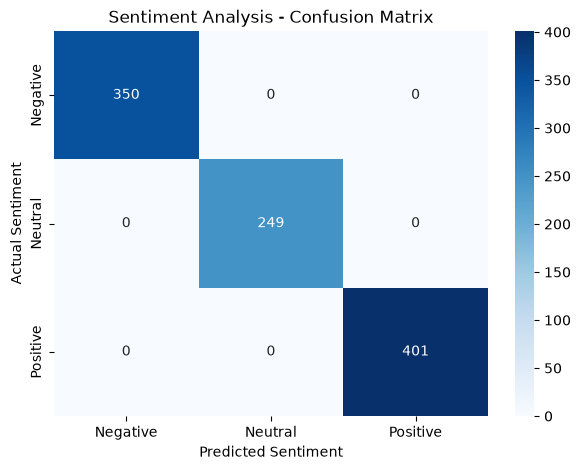

In [104]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()

In [106]:
def predict_sentiment(review):

    review = review.lower()

    # Text preprocessing
    review = re.sub(r"[^a-zA-Z\s]", "", review)

    tokens = word_tokenize(review)

    stop_words = set(stopwords.words("english"))
    stop_words = stop_words - {"not", "no", "nor"}

    filtered_words = [
        word for word in tokens if word not in stop_words
    ]

    final_review = " ".join(filtered_words)

    # TF-IDF transformation
    review_vector = tfidf.transform([final_review])

    # Prediction
    prediction = model.predict(review_vector)

    return prediction[0]

In [107]:
review = "I really love this product. It is amazing!"

result = predict_sentiment(review)

print("Review:", review)
print("Predicted Sentiment:", result)

Review: I really love this product. It is amazing!
Predicted Sentiment: Positive


In [108]:
print(predict_sentiment("This product is very bad"))
print(predict_sentiment("The service is excellent"))
print(predict_sentiment("The product is okay"))

Neutral
Positive
Neutral


In [109]:
import pickle
import os

# Create model folder
os.makedirs("model", exist_ok=True)

# Save Machine Learning Model
with open("model/sentiment_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save TF-IDF Vectorizer
with open("model/tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("Model and TF-IDF saved successfully!")

Model and TF-IDF saved successfully!


In [110]:
os.listdir("model")

['sentiment_model.pkl', 'tfidf_vectorizer.pkl']

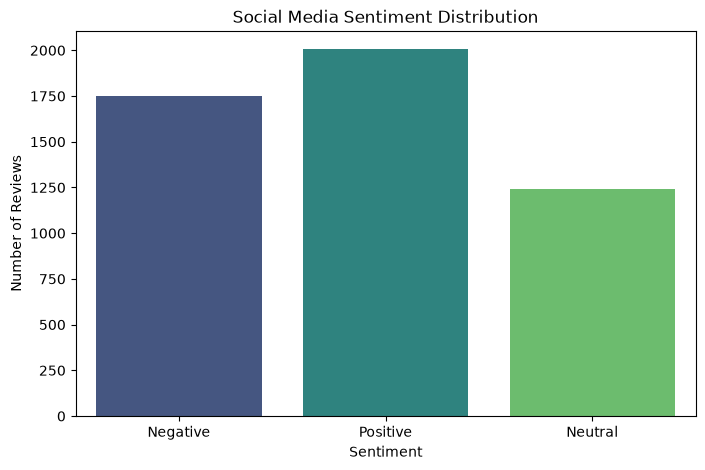

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="sentiment",
    hue="sentiment",
    palette="viridis",
    legend=False
)

plt.title("Social Media Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.savefig("sentiment_chart.png", dpi=300, bbox_inches="tight")
plt.show()

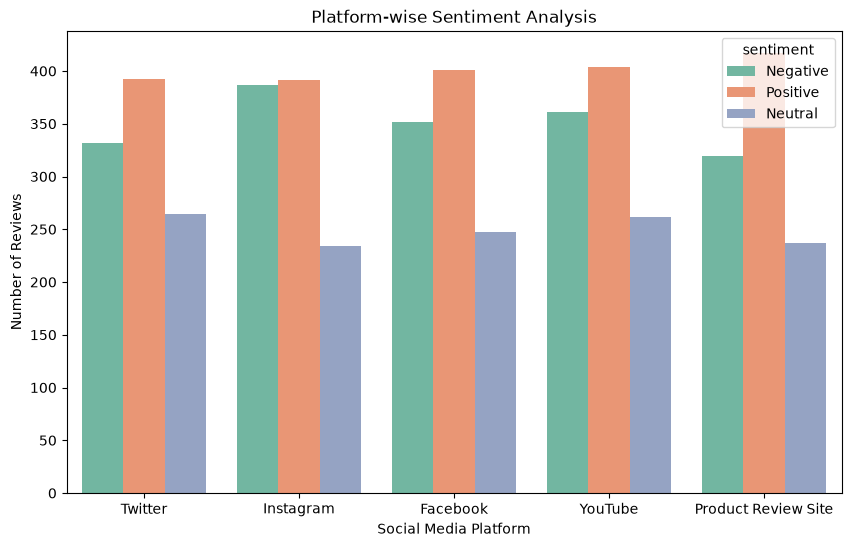

In [112]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x="platform",
    hue="sentiment",
    palette="Set2"
)

plt.title("Platform-wise Sentiment Analysis")
plt.xlabel("Social Media Platform")
plt.ylabel("Number of Reviews")

plt.savefig("platform_sentiment_chart.png", dpi=300, bbox_inches="tight")
plt.show()

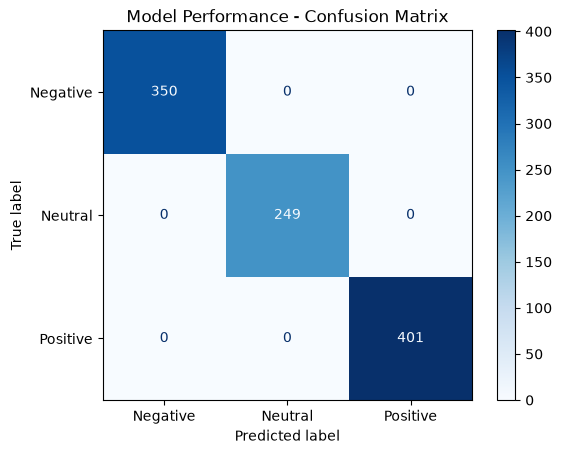

In [113]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Model Performance - Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [114]:
print(os.listdir("."))

['.ipynb_checkpoints', 'cleaned_social_media_reviews.csv', 'confusion_matrix.png', 'feature_columns.pkl', 'Linera regration.ipynb', 'Loan_approval_predication-Copy1.ipynb', 'Loan_approval_predication.ipynb', 'Loan_py', 'model', 'model.pkl', 'My Music', 'My Pictures', 'My Videos', 'negative_wordcloud.png', 'platform_sentiment_chart.png', 'positive_wordcloud.png', 'RAG_Company_Document_Chatbot.ipynb.ipynb', 'Randome forest_ML_project.ipynb', 'scaler.pkl', 'seaborn.ipynb', 'sentiment_chart.png', 'Social_Media_Sentiment_Analysis.ipynb', 'social_media_wordcloud.png', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb']


In [115]:
import os

project_folder = "Social-Media-Sentiment-Analysis"

os.makedirs(project_folder, exist_ok=True)
os.makedirs(project_folder + "/dataset", exist_ok=True)
os.makedirs(project_folder + "/notebooks", exist_ok=True)
os.makedirs(project_folder + "/images", exist_ok=True)
os.makedirs(project_folder + "/model", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [117]:
import os

print("Current Folder:", os.getcwd())

print("\nAvailable CSV Files:")
for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

Current Folder: C:\Users\SAVITRI\Documents

Available CSV Files:
cleaned_social_media_reviews.csv


In [119]:
import os

for root, dirs, files in os.walk(os.path.expanduser("~")):
    for file in files:
        if file == "social_media_sentiment_dataset.csv":
            print(os.path.join(root, file))

C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv


In [120]:
import os

print("Current Location:", os.getcwd())
print("CSV Files:", [f for f in os.listdir() if f.endswith(".csv")])

Current Location: C:\Users\SAVITRI\Documents
CSV Files: ['cleaned_social_media_reviews.csv']


In [121]:
import os

found = []

for root, dirs, files in os.walk(r"C:\Users\SAVITRI\Downloads"):
    for file in files:
        if file.endswith(".csv"):
            found.append(os.path.join(root, file))

for path in found:
    print(path)

C:\Users\SAVITRI\Downloads\bank_transactions_large (1).csv
C:\Users\SAVITRI\Downloads\bank_transactions_large.csv
C:\Users\SAVITRI\Downloads\condition.csv
C:\Users\SAVITRI\Downloads\health_dataset.csv
C:\Users\SAVITRI\Downloads\HR_Analytics-4.csv
C:\Users\SAVITRI\Downloads\Image Datasets.csv
C:\Users\SAVITRI\Downloads\loan_approval_dataset.csv
C:\Users\SAVITRI\Downloads\monthly-payroll-2026-05.csv
C:\Users\SAVITRI\Downloads\monthly-payroll-2026-06 (1).csv
C:\Users\SAVITRI\Downloads\monthly-payroll-2026-06.csv
C:\Users\SAVITRI\Downloads\Organ.csv
C:\Users\SAVITRI\Downloads\payment-history-santosh.csv
C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv
C:\Users\SAVITRI\Downloads\Titanic (1).csv
C:\Users\SAVITRI\Downloads\Titanic.csv
C:\Users\SAVITRI\Downloads\Loan_Prediction\loan_approval_dataset.csv
C:\Users\SAVITRI\Downloads\Loan_Prediction\Loan-Approval-Prediction\loan_approval_dataset.csv
C:\Users\SAVITRI\Downloads\Student-Perfomance-Prediction-main\Artifacts\Raw_Data.csv
C

In [123]:
source = r"C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv"

destination = project_folder + "/dataset/social_media_reviews.csv"

shutil.copy(source, destination)

print("Dataset copied successfully!")

Dataset copied successfully!


In [126]:
import os

folder = r"C:\Users\SAVITRI\Downloads"

print("Folder exists:", os.path.isdir(folder))

if os.path.isdir(folder):
    for file in os.listdir(folder):
        if file.endswith(".csv"):
            print(file)

Folder exists: True
bank_transactions_large (1).csv
bank_transactions_large.csv
condition.csv
health_dataset.csv
HR_Analytics-4.csv
Image Datasets.csv
loan_approval_dataset.csv
monthly-payroll-2026-05.csv
monthly-payroll-2026-06 (1).csv
monthly-payroll-2026-06.csv
Organ.csv
payment-history-santosh.csv
social_media_sentiment_dataset.csv
Titanic (1).csv
Titanic.csv


In [127]:
import shutil

source = r"C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv"

destination = os.path.join(
    project_folder,
    "dataset",
    "social_media_reviews.csv"
)

shutil.copy(source, destination)

print("Dataset copied successfully!")

Dataset copied successfully!


In [129]:
import os

for root, dirs, files in os.walk(r"C:\Users\SAVITRI"):
    for file in files:
        if "social_media" in file.lower() and file.endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\SAVITRI\Documents\cleaned_social_media_reviews.csv
C:\Users\SAVITRI\Documents\Social-Media-Sentiment-Analysis\dataset\social_media_reviews.csv
C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv


In [130]:
import shutil
import os

source = r"C:\Users\SAVITRI\Downloads\social_media_sentiment_dataset.csv"

destination = os.path.join(
    project_folder,
    "dataset",
    "social_media_reviews.csv"
)

shutil.copy(source, destination)

print("Dataset copied successfully!")

Dataset copied successfully!


In [131]:
df_clean.to_csv(
    os.path.join(project_folder, "dataset", "cleaned_social_media_reviews.csv"),
    index=False
)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [132]:
import os
import shutil

os.makedirs(os.path.join(project_folder, "model"), exist_ok=True)

shutil.copy(
    "model/sentiment_model.pkl",
    os.path.join(project_folder, "model", "sentiment_model.pkl")
)

shutil.copy(
    "model/tfidf_vectorizer.pkl",
    os.path.join(project_folder, "model", "tfidf_vectorizer.pkl")
)

print("Both Model Files Copied Successfully!")

Both Model Files Copied Successfully!


In [133]:
print("Current Folder:", os.getcwd())
print("Available Files:", os.listdir())
print("Model Folder:", os.listdir("model") if os.path.exists("model") else "Not Found")

Current Folder: C:\Users\SAVITRI\Documents
Available Files: ['.ipynb_checkpoints', 'cleaned_social_media_reviews.csv', 'confusion_matrix.png', 'feature_columns.pkl', 'Linera regration.ipynb', 'Loan_approval_predication-Copy1.ipynb', 'Loan_approval_predication.ipynb', 'Loan_py', 'model', 'model.pkl', 'My Music', 'My Pictures', 'My Videos', 'negative_wordcloud.png', 'platform_sentiment_chart.png', 'positive_wordcloud.png', 'RAG_Company_Document_Chatbot.ipynb.ipynb', 'Randome forest_ML_project.ipynb', 'scaler.pkl', 'seaborn.ipynb', 'sentiment_chart.png', 'Social-Media-Sentiment-Analysis', 'Social_Media_Sentiment_Analysis.ipynb', 'social_media_wordcloud.png', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb']
Model Folder: ['sentiment_model.pkl', 'tfidf_vectorizer.pkl']


In [134]:
import os
import shutil

images_folder = os.path.join(project_folder, "images")
os.makedirs(images_folder, exist_ok=True)

chart_files = [
    "sentiment_chart.png",
    "platform_sentiment_chart.png",
    "confusion_matrix.png",
    "social_media_wordcloud.png"
]

for file in chart_files:
    if os.path.exists(file):
        shutil.copy(file, os.path.join(images_folder, file))
        print(file, "Copied Successfully")
    else:
        print(file, "Not Found")

sentiment_chart.png Copied Successfully
platform_sentiment_chart.png Copied Successfully
confusion_matrix.png Copied Successfully
social_media_wordcloud.png Copied Successfully


In [135]:
for root, dirs, files in os.walk(project_folder):
    print("\nFolder:", root)
    for file in files:
        print("  -", file)


Folder: Social-Media-Sentiment-Analysis

Folder: Social-Media-Sentiment-Analysis\dataset
  - cleaned_social_media_reviews.csv
  - social_media_reviews.csv

Folder: Social-Media-Sentiment-Analysis\images
  - confusion_matrix.png
  - platform_sentiment_chart.png
  - sentiment_chart.png
  - social_media_wordcloud.png

Folder: Social-Media-Sentiment-Analysis\model
  - sentiment_model.pkl
  - tfidf_vectorizer.pkl

Folder: Social-Media-Sentiment-Analysis\notebooks


In [136]:
import os

print("Current Notebook Folder:")
print(os.getcwd())

Current Notebook Folder:
C:\Users\SAVITRI\Documents


In [137]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
nltk
wordcloud
"""

file_path = os.path.join(project_folder, "requirements.txt")

with open(file_path, "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [138]:
with open(file_path, "r") as file:
    print(file.read())

pandas
numpy
matplotlib
seaborn
scikit-learn
nltk
wordcloud


In [139]:
import os

print("Project Location:")
print(os.path.abspath(project_folder))

print("\nNotebook Folder:")
print(os.path.abspath(os.path.join(project_folder, "notebooks")))

Project Location:
C:\Users\SAVITRI\Documents\Social-Media-Sentiment-Analysis

Notebook Folder:
C:\Users\SAVITRI\Documents\Social-Media-Sentiment-Analysis\notebooks


In [140]:
for root, dirs, files in os.walk(project_folder):
    print("\n", root)
    for file in files:
        print("  ", file)


 Social-Media-Sentiment-Analysis
   requirements.txt

 Social-Media-Sentiment-Analysis\dataset
   cleaned_social_media_reviews.csv
   social_media_reviews.csv

 Social-Media-Sentiment-Analysis\images
   confusion_matrix.png
   platform_sentiment_chart.png
   sentiment_chart.png
   social_media_wordcloud.png

 Social-Media-Sentiment-Analysis\model
   sentiment_model.pkl
   tfidf_vectorizer.pkl

 Social-Media-Sentiment-Analysis\notebooks


In [144]:
import os

notebook_folder = os.path.join(project_folder, "notebooks")

print(os.listdir(notebook_folder))

[]
